In [3]:
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_recall_fscore_support, f1_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.preprocessing import StandardScaler

from google.colab import drive
drive.mount('/content/drive')

output_dir = "/content/drive/MyDrive/Colab Notebooks/E2_Output"
folders = ["evaluation", "models", "preprocessing"]

for folder in folders:
    os.makedirs(os.path.join(output_dir, folder), exist_ok=True)

print("Đã tạo xong cấu trúc thư mục trên Google Drive:")
for root, dirs, files in os.walk(output_dir):
    print(root)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Đã tạo xong cấu trúc thư mục trên Google Drive:
/content/drive/MyDrive/Colab Notebooks/E2_Output
/content/drive/MyDrive/Colab Notebooks/E2_Output/evaluation
/content/drive/MyDrive/Colab Notebooks/E2_Output/models
/content/drive/MyDrive/Colab Notebooks/E2_Output/preprocessing


In [4]:
# Đọc file feature table
data_path = '/content/drive/MyDrive/Colab Notebooks/data/honduras_features.csv'
df = pd.read_csv(data_path)
features = ['tweet_count', 'avg_text_length', 'url_ratio', 'hashtag_ratio', 'mention_ratio', 'retweet_ratio']

# Chia tập (giữ account-level split)
train_df = df[df['split'] == 'train']
val_df = df[df['split'] == 'validation']
test_df = df[df['split'] == 'test']

X_train, y_train = train_df[features], train_df['label']
X_val, y_val = val_df[features], val_df['label']
X_test, y_test = test_df[features], test_df['label']

# Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Xuất file scaler.joblib vào thư mục preprocessing
scaler_path = os.path.join(output_dir, "preprocessing", "scaler.joblib")
joblib.dump(scaler, scaler_path)
print(f"Đã lưu Scaler tại: {scaler_path}")

Đã lưu Scaler tại: /content/drive/MyDrive/Colab Notebooks/E2_Output/preprocessing/scaler.joblib


In [5]:
# 1. DummyClassifier
dummy = DummyClassifier(strategy='prior')
dummy.fit(X_train_scaled, y_train)

# 2. Logistic Regression (class_weight='balanced')
lr = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)

# Lưu mô hình bằng joblib
dummy_path = os.path.join(output_dir, "models", "dummyclassifier.joblib")
lr_path = os.path.join(output_dir, "models", "logisticregression.joblib")

joblib.dump(dummy, dummy_path)
joblib.dump(lr, lr_path)
print(f"Đã lưu các file model (.joblib) vào thư mục {os.path.join(output_dir, 'models')}")

Đã lưu các file model (.joblib) vào thư mục /content/drive/MyDrive/Colab Notebooks/E2_Output/models


In [6]:
def evaluate_model(model, X, y_true):
    y_pred = model.predict(X)
    y_prob_bad = model.predict_proba(X)[:, 0]

    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    y_true_bad_binary = (y_true == 0).astype(int)
    ap = average_precision_score(y_true_bad_binary, y_prob_bad)

    return {
        'Bad_Precision': p[0], 'Bad_Recall': r[0], 'Bad_F1': f1[0],
        'Macro_F1': macro_f1, 'Bad_PR_AUC': ap
    }

# Thu thập kết quả
metrics = []
for split_name, X_split, y_split in [('Validation', X_val_scaled, y_val), ('Test', X_test_scaled, y_test)]:
    for model_name, model in [('DummyClassifier', dummy), ('LogisticRegression', lr)]:
        res = evaluate_model(model, X_split, y_split)
        res['Model'] = model_name
        res['Split'] = split_name
        metrics.append(res)

# Xuất metrics.csv
metrics_df = pd.DataFrame(metrics)[['Model', 'Split', 'Bad_Precision', 'Bad_Recall', 'Bad_F1', 'Macro_F1', 'Bad_PR_AUC']]
metrics_path = os.path.join(output_dir, "evaluation", "e2_metrics.csv")
metrics_df.to_csv(metrics_path, index=False)

# Xuất predictions.csv
for model_name, model, col_pred, col_prob in [('Dummy', dummy, 'dummy_pred', 'dummy_prob_bad'),
                                              ('LR', lr, 'lr_pred', 'lr_prob_bad')]:
    val_df.loc[:, col_pred] = model.predict(X_val_scaled)
    val_df.loc[:, col_prob] = model.predict_proba(X_val_scaled)[:, 0]
    test_df.loc[:, col_pred] = model.predict(X_test_scaled)
    test_df.loc[:, col_prob] = model.predict_proba(X_test_scaled)[:, 0]

all_preds = pd.concat([val_df[['account_id', 'label', 'split', 'dummy_pred', 'dummy_prob_bad', 'lr_pred', 'lr_prob_bad']],
                       test_df[['account_id', 'label', 'split', 'dummy_pred', 'dummy_prob_bad', 'lr_pred', 'lr_prob_bad']]])
preds_path = os.path.join(output_dir, "evaluation", "e2_predictions.csv")
all_preds.to_csv(preds_path, index=False)

# Tạo file config.json giả lập
config_data = {
    "project": "Honduras Bot Detection",
    "phase": "E2 - Baseline Classification",
    "features": features,
    "models": ["DummyClassifier", "LogisticRegression"]
}
with open(os.path.join(output_dir, "e2_config.json"), 'w') as f:
    json.dump(config_data, f, indent=4)

print(f"Đã xuất metrics, predictions và config.json thành công!")
display(metrics_df)

/tmp/ipykernel_1325/3678487786.py:32: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  val_df.loc[:, col_pred] = model.predict(X_val_scaled)
/tmp/ipykernel_1325/3678487786.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  val_df.loc[:, col_prob] = model.predict_proba(X_val_scaled)[:, 0]
/tmp/ipykernel_1325/3678487786.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation:

Đã xuất metrics, predictions và config.json thành công!


,Model,Split,Bad_Precision,Bad_Recall,Bad_F1,Macro_F1,Bad_PR_AUC
0,DummyClassifier,Validation,0.000000,0.000000,0.000000,0.497911,0.008323
1,LogisticRegression,Validation,0.091134,0.983957,0.166818,0.561902,0.564399
2,DummyClassifier,Test,0.000000,0.000000,0.000000,0.497916,0.008300
3,LogisticRegression,Test,0.089131,0.965147,0.163191,0.559996,0.471164


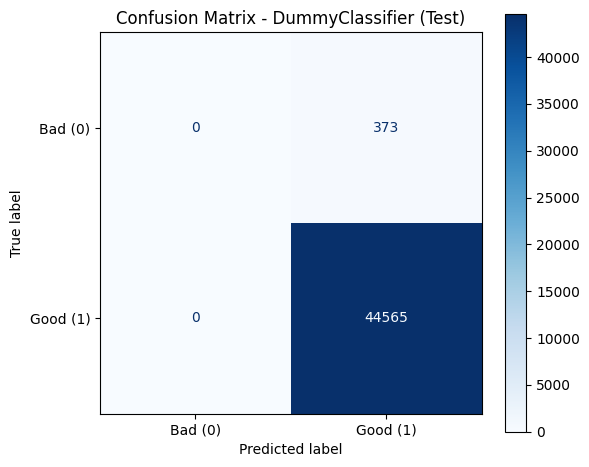

Đã lưu ảnh: /content/drive/MyDrive/Colab Notebooks/E2_Output/evaluation/confusion_matrix_DummyClassifier.png


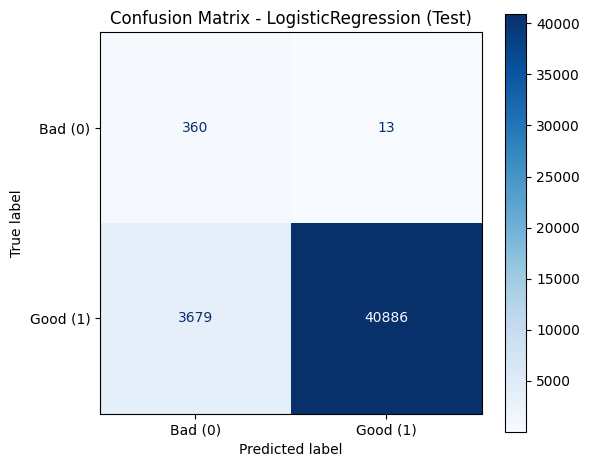

Đã lưu ảnh: /content/drive/MyDrive/Colab Notebooks/E2_Output/evaluation/confusion_matrix_LogisticRegression.png


In [7]:
def save_confusion_matrix(model, model_name, X_test, y_test, output_folder):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Bad (0)', 'Good (1)'])

    fig, ax = plt.subplots(figsize=(6, 5))
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    plt.title(f'Confusion Matrix - {model_name} (Test)')

    # Lưu file PNG
    img_path = os.path.join(output_folder, f"confusion_matrix_{model_name}.png")
    plt.tight_layout()
    plt.savefig(img_path, dpi=300)
    plt.show()
    print(f"Đã lưu ảnh: {img_path}")

eval_dir = os.path.join(output_dir, "evaluation")
save_confusion_matrix(dummy, "DummyClassifier", X_test_scaled, y_test, eval_dir)
save_confusion_matrix(lr, "LogisticRegression", X_test_scaled, y_test, eval_dir)